# Proyek ML: Prediksi Churn Pelanggan Telco (CRISP-DM)

Dataset: Telco Customer Churn (Kaggle)  
Algoritma: Logistic Regression, Decision Tree, Random Forest

## 1. Business Understanding
- **Masalah:** perusahaan telekomunikasi kehilangan pelanggan yang berhenti berlangganan (churn).
- **Tujuan:** memprediksi pelanggan yang berpotensi churn agar bisa dilakukan tindakan retensi.
- **Jenis masalah:** klasifikasi biner (Churn: Yes/No).
- **Metrik utama:** Recall dan F1-score kelas churn.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
print("Data berhasil dimuat:", df.shape)

Data berhasil dimuat: (7043, 21)


## 2. Data Understanding

In [2]:
display(df.head())
print("Shape:", df.shape)
print()
df.info()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Shape: (7043, 21)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 

In [3]:
display(df.describe())
print("Missing value (NaN):\n", df.isnull().sum())
print("\nDuplikat:", df.duplicated().sum())
print("\nJumlah tiap kelas Churn:\n", df["Churn"].value_counts())
print("\nPersentase Churn:\n", df["Churn"].value_counts(normalize=True).round(3))

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


Missing value (NaN):
 customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Duplikat: 0

Jumlah tiap kelas Churn:
 Churn
No     5174
Yes    1869
Name: count, dtype: int64

Persentase Churn:
 Churn
No     0.735
Yes    0.265
Name: proportion, dtype: float64


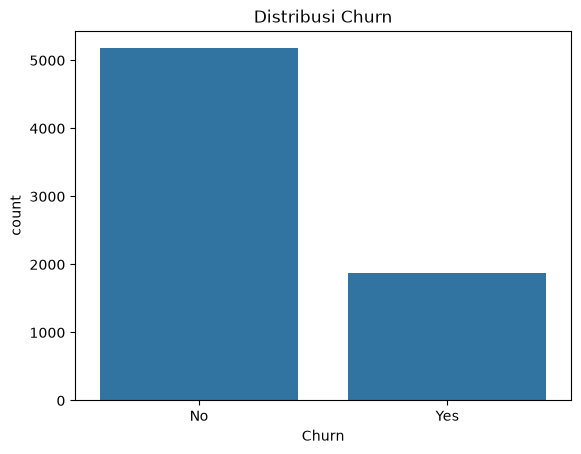

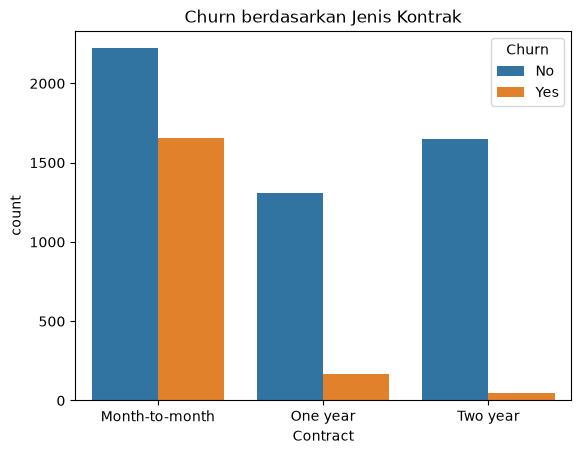

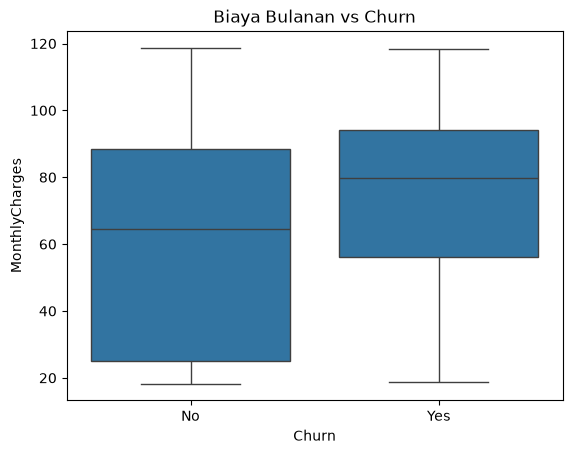

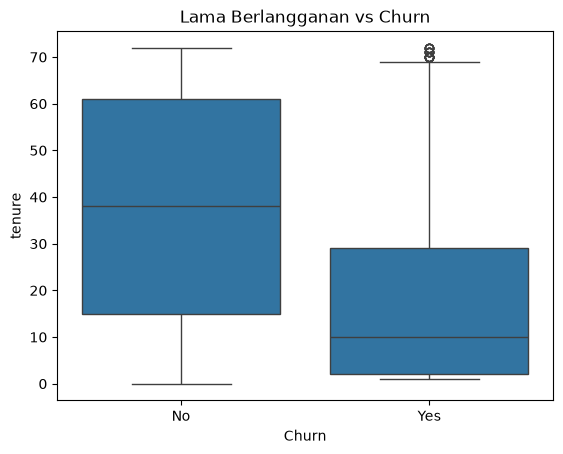

In [4]:
# Distribusi churn
sns.countplot(x="Churn", data=df)
plt.title("Distribusi Churn")
plt.show()

# Churn berdasarkan jenis kontrak
sns.countplot(x="Contract", hue="Churn", data=df)
plt.title("Churn berdasarkan Jenis Kontrak")
plt.show()

# Biaya bulanan vs churn
sns.boxplot(x="Churn", y="MonthlyCharges", data=df)
plt.title("Biaya Bulanan vs Churn")
plt.show()

# Lama berlangganan vs churn
sns.boxplot(x="Churn", y="tenure", data=df)
plt.title("Lama Berlangganan vs Churn")
plt.show()

## 3. Data Preparation

In [5]:
# 1. Hapus kolom ID
df = df.drop("customerID", axis=1)

# 2. Ubah TotalCharges ke angka (spasi kosong jadi NaN)
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Missing value TotalCharges:", df["TotalCharges"].isnull().sum())

# 3. Isi missing value dengan median
df["TotalCharges"] = df["TotalCharges"].fillna(df["TotalCharges"].median())
print("Setelah diisi:", df["TotalCharges"].isnull().sum())

# 4. Ubah target menjadi 0/1
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})
print(df["Churn"].value_counts())

Missing value TotalCharges: 11
Setelah diisi: 0
Churn
0    5174
1    1869
Name: count, dtype: int64


tenure: 0 outlier
MonthlyCharges: 0 outlier
TotalCharges: 0 outlier


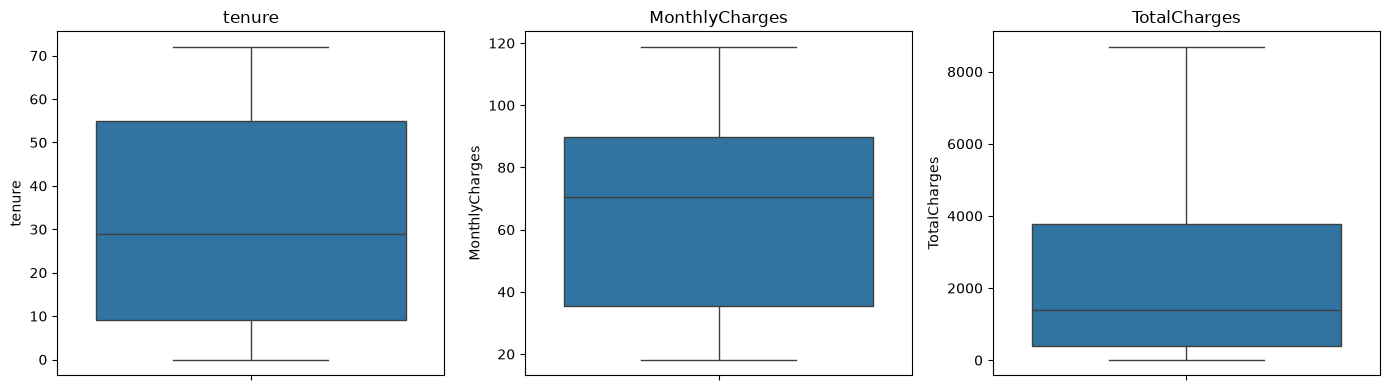

In [6]:
# Cek outlier dengan metode IQR
for col in ["tenure", "MonthlyCharges", "TotalCharges"]:
    Q1, Q3 = df[col].quantile([0.25, 0.75])
    IQR = Q3 - Q1
    batas_bawah, batas_atas = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    jumlah = ((df[col] < batas_bawah) | (df[col] > batas_atas)).sum()
    print(f"{col}: {jumlah} outlier")

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["tenure", "MonthlyCharges", "TotalCharges"]):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

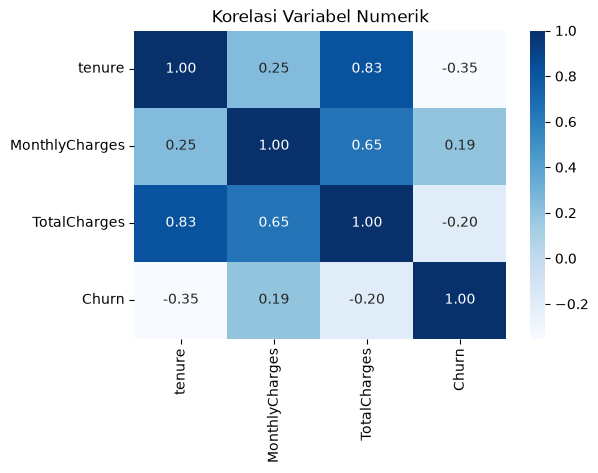

In [7]:
# Korelasi antar variabel numerik
plt.figure(figsize=(6, 4))
sns.heatmap(df[["tenure", "MonthlyCharges", "TotalCharges", "Churn"]].corr(),
            annot=True, cmap="Blues", fmt=".2f")
plt.title("Korelasi Variabel Numerik")
plt.show()

In [8]:
# Feature engineering
# 1. Kelompok lama berlangganan
df["tenure_group"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=["0-12", "13-24", "25-48", "49-72"]
).astype(str)

# 2. Jumlah layanan tambahan yang dipakai
service_cols = ["PhoneService", "MultipleLines", "OnlineSecurity", "OnlineBackup",
                "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
df["num_services"] = (df[service_cols] == "Yes").sum(axis=1)

# 3. Rata-rata biaya per bulan berlangganan
df["avg_charge"] = df["TotalCharges"] / (df["tenure"] + 1)

display(df[["tenure", "tenure_group", "num_services", "avg_charge"]].head())

,tenure,tenure_group,num_services,avg_charge
0,1,0-12,1,14.925000
1,34,25-48,3,53.985714
2,2,0-12,3,36.050000
3,45,25-48,3,40.016304
4,2,0-12,1,50.550000


In [9]:
# Split data (sebelum scaling/encoding agar tidak terjadi data leakage)
# Perbaikan kompatibilitas: ubah kolom teks ke tipe object
# (pandas versi baru memakai tipe "str" yang belum didukung scikit-learn lama)
for col in df.select_dtypes(exclude="number").columns:
    df[col] = df[col].astype(object)

from sklearn.model_selection import train_test_split

X = df.drop("Churn", axis=1)
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Proporsi churn di train:\n", y_train.value_counts(normalize=True).round(3))

Train: (5634, 22) | Test: (1409, 22)
Proporsi churn di train:
 Churn
0    0.735
1    0.265
Name: proportion, dtype: float64


In [10]:
# Preprocessor: scaling untuk numerik, one-hot encoding untuk kategorikal
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

num_cols = X_train.select_dtypes(include="number").columns
cat_cols = X_train.select_dtypes(exclude="number").columns

print("Kolom numerik   :", list(num_cols))
print("Kolom kategorikal:", list(cat_cols))

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
])

Kolom numerik   : ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'num_services', 'avg_charge']
Kolom kategorikal: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'tenure_group']


## 4. Modeling dan Tuning
Imbalance ditangani dengan `class_weight="balanced"`. Tuning menggunakan GridSearchCV dengan scoring F1.

In [11]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

models = {
    "Logistic Regression": (
        LogisticRegression(class_weight="balanced", max_iter=1000),
        {"model__C": [0.01, 0.1, 1, 10]}
    ),
    "Decision Tree": (
        DecisionTreeClassifier(class_weight="balanced", random_state=42),
        {"model__max_depth": [3, 5, 7, 10],
         "model__min_samples_split": [2, 10, 20],
         "model__criterion": ["gini", "entropy"]}
    ),
    "Random Forest": (
        RandomForestClassifier(class_weight="balanced", random_state=42),
        {"model__n_estimators": [100, 200],
         "model__max_depth": [5, 10, None],
         "model__min_samples_split": [2, 10]}
    ),
}

best_models = {}

for name, (model, params) in models.items():
    print(f"Melatih {name} ...")
    pipe = Pipeline([("prep", preprocessor), ("model", model)])
    # Jika muncul error terkait n_jobs di Windows, ganti n_jobs=-1 menjadi n_jobs=1
    grid = GridSearchCV(pipe, params, cv=5, scoring="f1", n_jobs=-1)
    grid.fit(X_train, y_train)
    best_models[name] = grid.best_estimator_
    print("  Parameter terbaik:", grid.best_params_)
    print("  F1 CV terbaik    :", round(grid.best_score_, 4))
    print()

Melatih Logistic Regression ...
  Parameter terbaik: {'model__C': 1}
  F1 CV terbaik    : 0.6316

Melatih Decision Tree ...
  Parameter terbaik: {'model__criterion': 'gini', 'model__max_depth': 3, 'model__min_samples_split': 2}
  F1 CV terbaik    : 0.6204

Melatih Random Forest ...
  Parameter terbaik: {'model__max_depth': 10, 'model__min_samples_split': 10, 'model__n_estimators': 200}
  F1 CV terbaik    : 0.6357



## 5. Evaluation

In [12]:
from sklearn.metrics import classification_report

for name, model in best_models.items():
    print(f"=== {name} ===")
    print(classification_report(y_test, model.predict(X_test),
                                target_names=["Tidak Churn", "Churn"]))

=== Logistic Regression ===
              precision    recall  f1-score   support

 Tidak Churn       0.90      0.72      0.80      1035
       Churn       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409

=== Decision Tree ===
              precision    recall  f1-score   support

 Tidak Churn       0.90      0.73      0.81      1035
       Churn       0.51      0.78      0.62       374

    accuracy                           0.75      1409
   macro avg       0.71      0.76      0.71      1409
weighted avg       0.80      0.75      0.76      1409

=== Random Forest ===
              precision    recall  f1-score   support

 Tidak Churn       0.89      0.78      0.83      1035
       Churn       0.55      0.75      0.63       374

    accuracy                           0.77      1409
   macro avg       0.72      0.76      0.73      1409
we

In [13]:
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
                             recall_score, precision_score, f1_score,
                             accuracy_score, roc_auc_score)

hasil = []
for name, model in best_models.items():
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]
    hasil.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_proba),
    })

df_hasil = pd.DataFrame(hasil).set_index("Model").round(4)
display(df_hasil)

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic Regression,0.7374,0.5034,0.7807,0.6122,0.8462
Decision Tree,0.7459,0.5140,0.7834,0.6208,0.8144
Random Forest,0.7708,0.5503,0.7460,0.6334,0.8414


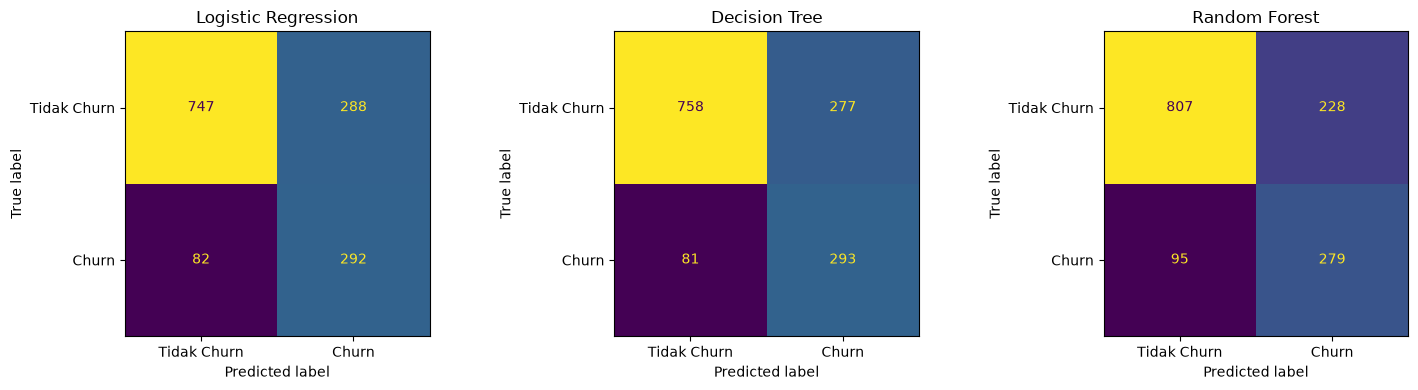

In [14]:
# Confusion matrix
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, model) in zip(axes, best_models.items()):
    cm = confusion_matrix(y_test, model.predict(X_test))
    ConfusionMatrixDisplay(cm, display_labels=["Tidak Churn", "Churn"]).plot(ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

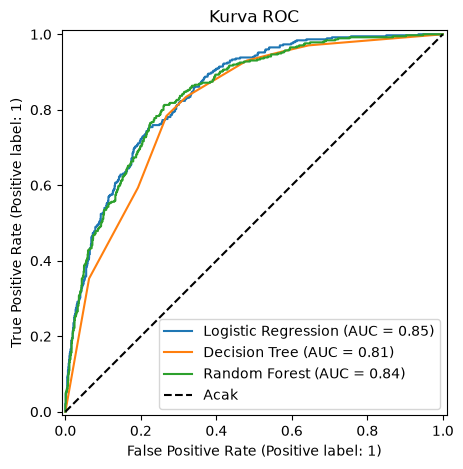

In [15]:
# Kurva ROC
from sklearn.metrics import RocCurveDisplay

fig, ax = plt.subplots(figsize=(6, 5))
for name, model in best_models.items():
    RocCurveDisplay.from_estimator(model, X_test, y_test, name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--", label="Acak")
ax.legend()
plt.title("Kurva ROC")
plt.show()

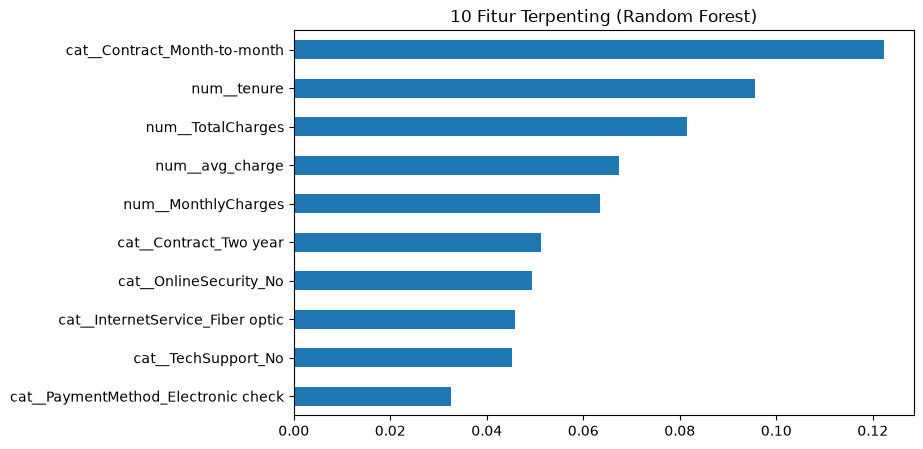

In [16]:
# Fitur terpenting (Random Forest)
rf = best_models["Random Forest"]
nama_fitur = rf.named_steps["prep"].get_feature_names_out()
importance = rf.named_steps["model"].feature_importances_

fi = pd.Series(importance, index=nama_fitur).sort_values(ascending=False).head(10)
fi.sort_values().plot(kind="barh", figsize=(8, 5), title="10 Fitur Terpenting (Random Forest)")
plt.show()

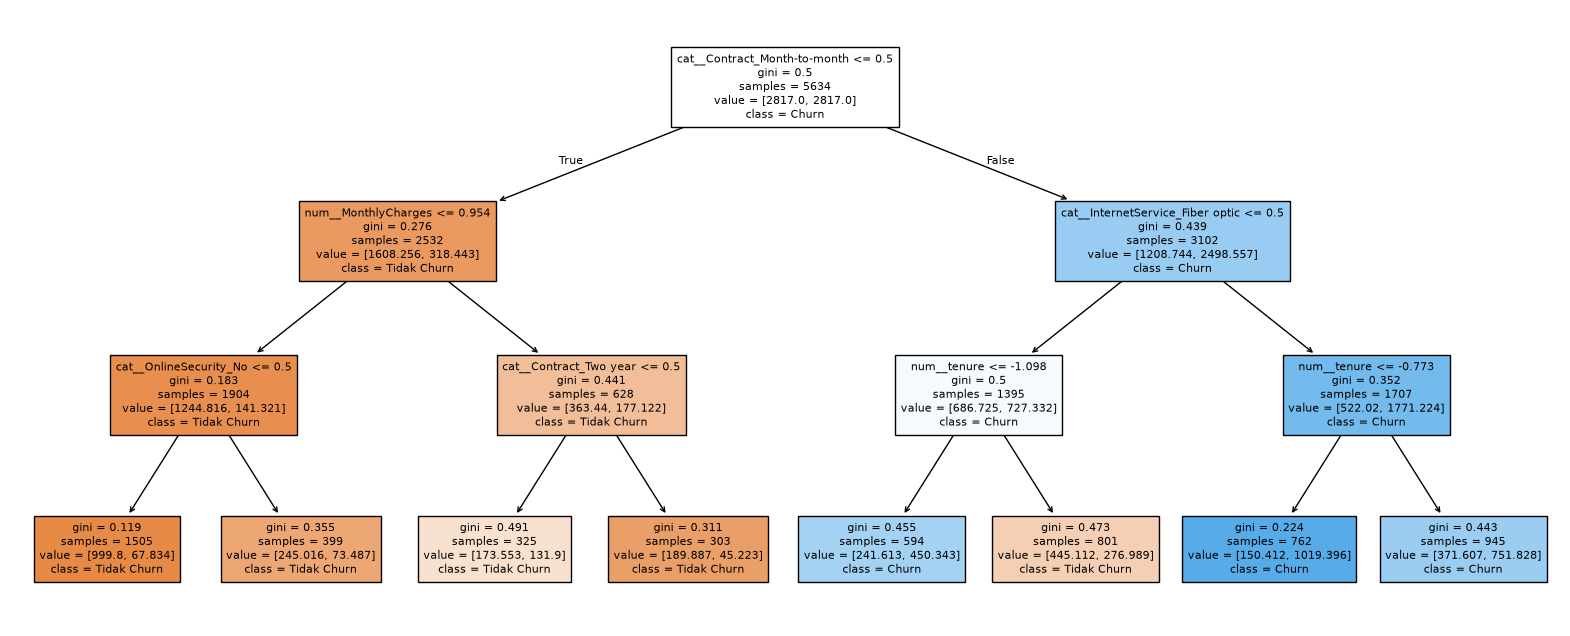

In [17]:
# Visualisasi Decision Tree (3 level teratas)
from sklearn.tree import plot_tree

dt = best_models["Decision Tree"]
plt.figure(figsize=(20, 8))
plot_tree(dt.named_steps["model"],
          feature_names=dt.named_steps["prep"].get_feature_names_out(),
          class_names=["Tidak Churn", "Churn"],
          max_depth=3, filled=True, fontsize=8)
plt.show()

## 6. Deployment: Simpan Model
Pilih model terbaik berdasarkan tabel `df_hasil` (prioritas Recall dan F1).

In [18]:
import joblib
import sklearn

# Ganti sesuai model terbaik menurut hasil evaluasimu.
# Default: model dengan F1 tertinggi.
nama_terbaik = df_hasil["F1"].idxmax()
print("Model terbaik (F1 tertinggi):", nama_terbaik)

joblib.dump(best_models[nama_terbaik], "model_churn.pkl")
print("Model disimpan ke model_churn.pkl")
print("Versi scikit-learn:", sklearn.__version__)

Model terbaik (F1 tertinggi): Random Forest
Model disimpan ke model_churn.pkl
Versi scikit-learn: 1.6.1


In [19]:
import sys, pandas as pd, sklearn, numpy as np
print(sys.executable)
print("pandas:", pd.__version__, "| sklearn:", sklearn.__version__, "| numpy:", np.__version__)

c:\Users\Alya Andina\AppData\Local\Programs\Python\Python313\python.exe
pandas: 2.2.3 | sklearn: 1.6.1 | numpy: 2.5.3
